<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT422_%7C_HW_2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 | HW 2.2: Probability and Random Variables

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## 2.2.1: Probability axiom
There are 5 samples given (S1-5) lined against events A and B which are used as a means to extend total sampling probability. This is meant to back the inherent idea that probability is measured between 1-0 as well as the idea that total probability of a set of samples is added to 1. In this case, the idea behind a negative probability is also proven false as seen belows. Along with the calculation of the union, the union matches the definition for an or statement where P(A) + P(B) - P(A and B) = P(A or B).

All probabilities are nonnegative: True
Total probability: 1.0

P(A) = 0.7
P(B) = 0.55

P(A and B) = 0.25
P(A or B) = 1.0

P(A) + P(B) - P(A and B) = 1.0
Union rule verified: True


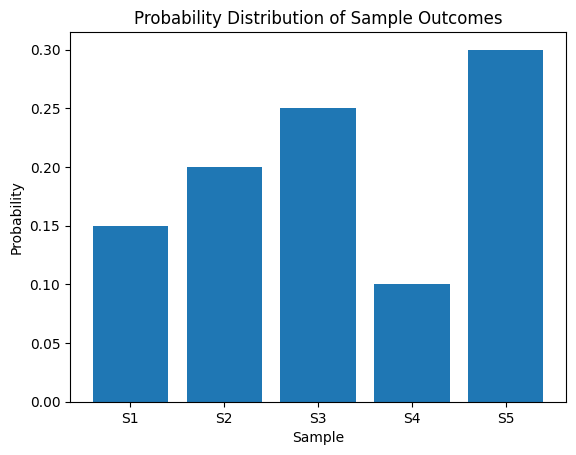

In [11]:
samples = np.array(["S1", "S2", "S3", "S4", "S5"])
probabilities = np.array([0.15, 0.20, 0.25, 0.10, 0.30])
A = np.array([True, False, True, False, True])
B = np.array([False, True, True, True, False])


print("All probabilities are nonnegative:", np.all(probabilities >= 0))
print("Total probability:", probabilities.sum())


p_a = probabilities[A].sum()
p_b = probabilities[B].sum()

p_intersection = probabilities[A & B].sum()
p_union = probabilities[A | B].sum()


print("\nP(A) =", round(p_a, 4))
print("P(B) =", round(p_b, 4))

print("\nP(A and B) =", round(p_intersection, 4))
print("P(A or B) =", round(p_union, 4))

print("\nP(A) + P(B) - P(A and B) =",  round(p_a + p_b - p_intersection, 4))
print("Union rule verified:",  np.isclose(p_union, p_a + p_b - p_intersection))


plt.bar(samples, probabilities)
plt.xlabel("Sample")
plt.ylabel("Probability")
plt.title("Probability Distribution of Sample Outcomes")
plt.show()

## 2.2.2: Conditional Probability
Conditional probability is used to describe the idea behind event given a situation (ie. the probability of a shark attack given you are in the water). This is done by the equation of P(A | B) = P(A and B) / P(B) if this were to be a typical independent situation it would be logical to assume that since P(A and B) = P(A)*P(B) that dividing by P(B) would give us P(A). Thus, if it were different then it would be possible to assume that there is some attributed dependence that is shifiting the expected P(A|B).

In [25]:
results = np.array([
    ["Control", "Success"],
    ["Control", "Failure"],
    ["Control", "Success"],
    ["Control", "Success"],
    ["Treatment", "Success"],
    ["Treatment", "Success"],
    ["Treatment", "Failure"],
    ["Treatment", "Success"],
    ["Treatment", "Success"],
    ["Treatment", "Failure"]
])

treatment = results[:, 0] == "Treatment"
success = results[:, 1] == "Success"

p_success = np.mean(success)
p_treatment = np.mean(treatment)
p_both = np.mean(treatment & success)


p_success_given_treatment = p_both / p_treatment
print("P(Success) =", round(p_success, 4))
print("P(Treatment) =", round(p_treatment, 4))


print("\nP(Success and Treatment) =", round(p_both, 4))
print("P(Success | Treatment) =", round(p_success_given_treatment, 4))


direct_probability = np.mean(success[treatment])
print("\nDirect calculation =",    round(direct_probability, 4))
print("Conditional probability verified:",   np.isclose(p_success_given_treatment, direct_probability))

P(Success) = 0.7
P(Treatment) = 0.6

P(Success and Treatment) = 0.4
P(Success | Treatment) = 0.6667

Direct calculation = 0.6667
Conditional probability verified: True


##2.2.3 | Discrete Random Variables
A discrete random variable can only take specific countable values. The number of trials in the listed example below is 4 upon which a probability mass function has assigned a probability to each number of successes. These all come in to add up to 1 for which they create a valid probability distribution.

PMF sums to 1: True
Total probability = 0.9999999999999999
E[X] = 2.2
Var(X) = 1.06
Std(X) = 1.0296
P(X >= 3) = 0.4


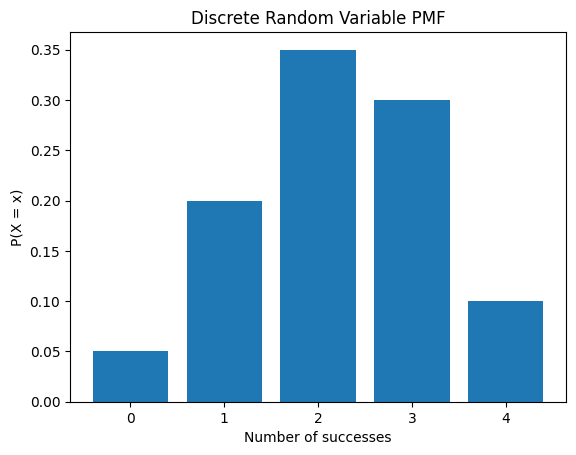

In [27]:
x = np.array([0, 1, 2, 3, 4])
pmf = np.array([0.05, 0.20, 0.35, 0.30, 0.10])


print("PMF sums to 1:", np.isclose(pmf.sum(), 1))
print("Total probability =", pmf.sum())


expected_value = np.sum(x * pmf)
variance = np.sum((x - expected_value) ** 2 * pmf)
standard_deviation = np.sqrt(variance)

print("E[X] =", round(expected_value, 4))
print("Var(X) =", round(variance, 4))
print("Std(X) =", round(standard_deviation, 4))


p_at_least_3 = pmf[x >= 3].sum()
print("P(X >= 3) =", round(p_at_least_3, 4))

plt.bar(x, pmf)
plt.xlabel("Number of successes")
plt.ylabel("P(X = x)")
plt.title("Discrete Random Variable PMF")
plt.xticks(x)
plt.show()

##2.2.4 | Continuous Random Variables
A continuous random variable can take any value within 2 numbers contrasting to a single integer or defined value. This allows us for a more uniform distribution. In the example prescribed, the continuous interval is set between 2 and 8 and is contant accross the interval. Regardless the area prescribed beneath the curve must be 1 which is examined below.

Lower bound = 2
Upper bound = 8
P(3 <= X <= 5) = 0.3333

Approximate total area = 1.0

P(X > 6) = 0.3333


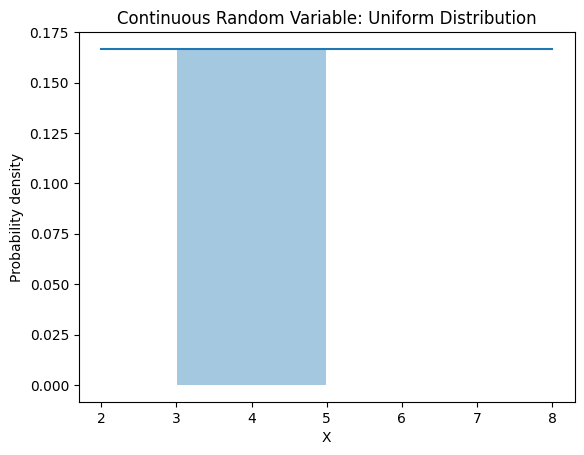

In [15]:
lower = 2
upper = 8

x = np.linspace(lower, upper, 500)
pdf = np.ones_like(x) / (upper - lower)

a = 3
b = 5
probability_interval = (b - a) / (upper - lower)
print("Lower bound =", lower)
print("Upper bound =", upper)
print("P(3 <= X <= 5) =", round(probability_interval, 4))


total_area = np.trapezoid(pdf, x)
print("\nApproximate total area =", round(total_area, 4))


p_greater_6 = (upper - 6) / (upper - lower)
print("\nP(X > 6) =", round(p_greater_6, 4))




plt.plot(x, pdf)
plt.fill_between(
    x[(x >= a) & (x <= b)],
    pdf[(x >= a) & (x <= b)],
    alpha=0.4
)
plt.xlabel("X")
plt.ylabel("Probability density")
plt.title("Continuous Random Variable: Uniform Distribution")
plt.show()

* I explained my sections in words before my code.
* I double checked my core numerical claims such as expression, matrix multiplication, norms, ...
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.